In [25]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/desolution01/messy-employee-dataset/Messy_Employee_dataset.csv


**1. Pengecekan Data Awal Karyawan**

In [26]:
# Membaca file dataset
df = pd.read_csv('/kaggle/input/datasets/desolution01/messy-employee-dataset/Messy_Employee_dataset.csv')

# Preview
df.head()


,Employee_ID,First_Name,Last_Name,Age,Department_Region,Status,Join_Date,Salary,Email,Phone,Performance_Score,Remote_Work
0,EMP1000,Bob,Davis,25.0,DevOps-California,Active,4/2/2021,59767.65,bob.davis@example.com,-1651623197,Average,True
1,EMP1001,Bob,Brown,NaN,Finance-Texas,Active,7/10/2020,65304.66,bob.brown@example.com,-1898471390,Excellent,True
2,EMP1002,Alice,Jones,NaN,Admin-Nevada,Pending,12/7/2023,88145.90,alice.jones@example.com,-5596363211,Good,True
3,EMP1003,Eva,Davis,25.0,Admin-Nevada,Inactive,11/27/2021,69450.99,eva.davis@example.com,-3476490784,Good,True
4,EMP1004,Frank,Williams,25.0,Cloud Tech-Florida,Active,1/5/2022,109324.61,frank.williams@example.com,-1586734256,Poor,False


In [27]:
# Identifikasi tipe data
df.info() 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1020 entries, 0 to 1019
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Employee_ID        1020 non-null   object 
 1   First_Name         1020 non-null   object 
 2   Last_Name          1020 non-null   object 
 3   Age                809 non-null    float64
 4   Department_Region  1020 non-null   object 
 5   Status             1020 non-null   object 
 6   Join_Date          1020 non-null   object 
 7   Salary             996 non-null    float64
 8   Email              1020 non-null   object 
 9   Phone              1020 non-null   int64  
 10  Performance_Score  1020 non-null   object 
 11  Remote_Work        1020 non-null   bool   
dtypes: bool(1), float64(2), int64(1), object(8)
memory usage: 88.8+ KB


In [28]:
# Melihat jumlah baris kosong per kolom
print("Jumlah Data Kosong per Kolom:")
print(df.isnull().sum()[df.isnull().sum() > 0])


Jumlah Data Kosong per Kolom:
Age       211
Salary     24
dtype: int64


In [29]:
# Mengecek duplikat jika ada
print("Jumlah duplikat:", df.duplicated().sum())

Jumlah duplikat: 0


**2. Identifikasi Masalah:**

* Format Tanggal (Join_Date) Unstandardized: Kolom tanggal bergabung (Join_Date) masih terbaca sebagai tipe data teks (object), sehingga perlu dikonversi menjadi format datetime agar dapat diolah berdasarkan atribut waktu (seperti tahun atau bulan).
* Kesalahan Penulisan / Typo pada Variabel Kategorikal: Terdapat ketidakkonsistenan atau typo pada entri data kategorikal (misalnya nilai nama departemen/wilayah), sehingga perlu dilakukan pembersihan atau standardisasi teks (text cleaning/string replacement) sebelum encoding.
* Tipe Data mostly masih object yang mana tidak diperbolehkan di machine learning yang membutuhkan tipe angka, bukan objek.
* Masih ada Missing Value atau komponen yang hilang
* Mencari duplikat data, tetapi karena tidak ada data duplikat maka step ini seharusnya tidak dibutuhkan. akan tetapi, in general saja saya memutuskan untuk menambahkan sebagai pembelajaran

**3. Proses**

* Mengubah Format tanggal

In [30]:
# a. Mengubah kolom Join_Date menjadi format tanggal (datetime)
df['Join_Date'] = pd.to_datetime(df['Join_Date'])

# b. Cek 
print(df['Join_Date'].dtype)

datetime64[ns]


> Pada tahap ini, saya melakukan konversi tipe data pada kolom Join_Date dari format teks (object) menjadi tipe data tanggal resmi yaitu datetime64[ns] menggunakan fungsi pd.to_datetime(). Langkah ini penting dilakukan agar data tanggal dapat dikenali secara hierarkis oleh sistem, sehingga mempermudah proses analisis berbasis waktu (time-series), ekstraksi informasi seperti tahun atau bulan bergabungnya karyawan, hingga pemrosesan data lanjutan dengan lebih akurat.

In [31]:
# melihat kategori apa saja yang ada di dalam kolom teks dan jumlah kemunculannya
print("--- Variasi data Department_Region ---")
print(df['Department_Region'].value_counts())

print("\n--- Variasi data Status ---")
print(df['Status'].value_counts())


--- Variasi data Department_Region ---
Department_Region
HR-Florida               41
DevOps-California        35
Sales-Nevada             35
Admin-Nevada             34
Admin-California         34
DevOps-Florida           34
Finance-Illinois         33
DevOps-New York          33
Sales-Florida            33
HR-New York              33
DevOps-Illinois          33
Finance-California       32
Sales-California         31
Sales-Illinois           30
Admin-Illinois           29
Finance-Texas            29
Cloud Tech-Texas         29
Cloud Tech-California    29
Finance-Nevada           29
Cloud Tech-Florida       28
DevOps-Nevada            27
DevOps-Texas             27
Sales-New York           26
HR-California            26
Admin-Florida            25
Cloud Tech-New York      24
Finance-Florida          24
HR-Illinois              24
HR-Nevada                24
HR-Texas                 23
Finance-New York         23
Sales-Texas              23
Admin-Texas              22
Admin-New York     

> Pada tahap ini, saya memeriksa variasi nilai pada kolom Department_Region dan Status menggunakan value_counts() untuk melihat distribusi frekuensi serta memastikan tidak ada kesalahan penulisan (typo). Hasilnya menunjukkan distribusi kategori yang teratur dan bersih dari anomali teks, sehingga data siap diolah lebih lanjut.

* Mengubah Tipe Data dari Object ke Angka

In [32]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df['Status_Encoded'] = le.fit_transform(df['Status'].astype(str))

print("Variasi unik:", df['Status_Encoded'].unique())
print(df[['Status', 'Status_Encoded']].head())

Variasi unik: [0 2 1]
     Status  Status_Encoded
0    Active               0
1    Active               0
2   Pending               2
3  Inactive               1
4    Active               0


> Pada tahap ini, saya melakukan categorical encoding menggunakan LabelEncoder dari scikit-learn untuk mengubah teks pada kolom Status menjadi format angka agar dapat diproses oleh algoritma machine learning. 
Hasilnya, data teks berhasil dikonversi secara otomatis dengan rincian:
> * Active = 0
> * Inactive = 1
> * Pending = 2
>   
> Dengan begitu, kolom Status kini sudah bertipe numerik, bersih dari missing value, dan siap digunakan untuk tahap analisis berikutnya.

* Mengisi Missing Value

In [33]:
# a. Mengisi data kosong pada Age dengan median umur karyawan
median_age = df['Age'].median()
df['Age'] = df['Age'].fillna(median_age)

# b. Mengisi data kosong pada Salary dengan median gaji karyawan
median_salary = df['Salary'].median()
df['Salary'] = df['Salary'].fillna(median_salary)

# c. Cek 
print(df.isnull().sum())


Employee_ID          0
First_Name           0
Last_Name            0
Age                  0
Department_Region    0
Status               0
Join_Date            0
Salary               0
Email                0
Phone                0
Performance_Score    0
Remote_Work          0
Status_Encoded       0
dtype: int64


> Pada tahap ini, kita menangani nilai yang hilang (missing values) pada kolom Age dan Salary menggunakan metode imputasi nilai median. Penggunaan nilai median dipilih karena lebih tahan terhadap outlier (pencilan) dibandingkan nilai rata-rata (mean), sehingga tidak merusak distribusi asli data. Setelah proses pengisian dilakukan, pengecekan akhir menunjukkan nilai 0 untuk seluruh kolom, yang menandakan dataset kini telah bersih 100% dari data kosong dan siap digunakan.

* Membersihkan Data Duplikat

In [34]:
# Mengecek dan langsung membersihkan duplikat jika ada
print("Jumlah duplikat:", df.duplicated().sum())
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)


Jumlah duplikat: 0


> Pada tahap ini, kita melakukan pemeriksaan data duplikat menggunakan fungsi duplicated() untuk memastikan integritas dan keunikan baris data. Berdasarkan hasil pengecekan, ditemukan bahwa jumlah data duplikat adalah 0, yang menunjukkan bahwa setiap baris dalam dataset sudah unik. Meskipun tidak ada duplikat yang perlu dihapus, langkah ini tetap dipertahankan sebagai prosedur standar kualitas data untuk memastikan tidak ada catatan ganda sebelum dilanjutkan ke tahap pemrosesan berikutnya.

**Visualisasi Data**

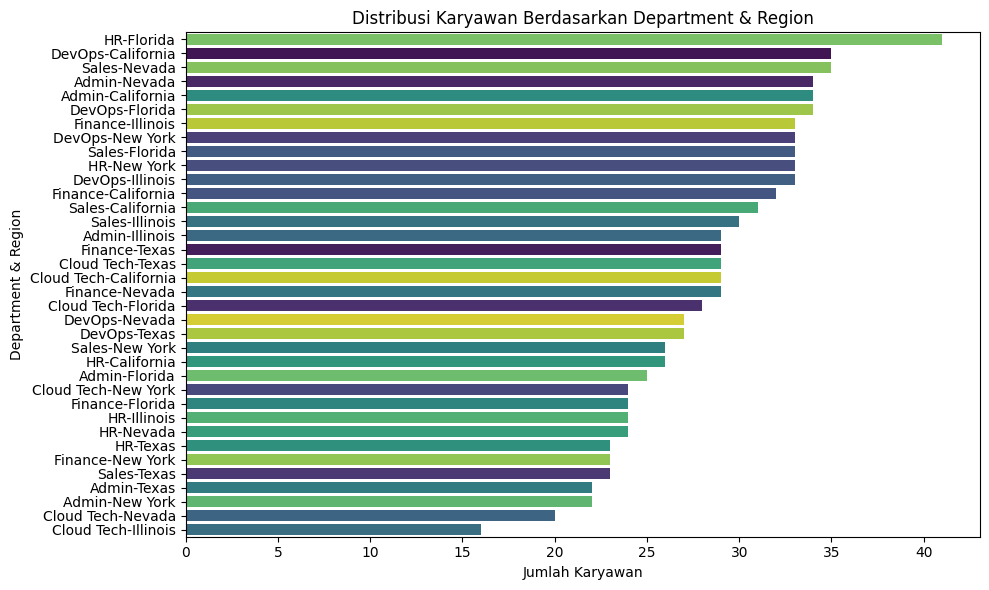

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

# Membuat visualisasi bar chart untuk distribusi Department_Region
plt.figure(figsize=(10, 6))
sns.countplot(
    data=df, 
    y='Department_Region', 
    order=df['Department_Region'].value_counts().index, 
    hue='Department_Region',  # Ditambahkan untuk menghilangkan warning
    palette='viridis',
    legend=False  # Menghilangkan legend yang tidak diperlukan
)
plt.title('Distribusi Karyawan Berdasarkan Department & Region')
plt.xlabel('Jumlah Karyawan')
plt.ylabel('Department & Region')
plt.tight_layout()
plt.show()

Selain menggunakan value_counts(), saya juga menambahkan visualisasi bar chart untuk melihat perbandingan distribusi data pada kolom Department_Region secara visual. Berdasarkan grafik di atas, terlihat bahwa setiap kategori departemen dan wilayah memiliki sebaran jumlah data yang cukup seimbang dan tertata rapi tanpa adanya anomali yang mencolok.